*Nombre de Grupos*:

*Integrantes*:

# **Deteccion de Esquinas por el Algoritmo de Harris**


**Motivacion**: Extraer features robustas de una escena que podamos ubicar entre distintas imagenes.

Aunque las ventanas con bordes son mejores candidatos que una superficie homogenea, siguen siendo constante en una direccion, haciendolas dificil de usar para ubicar.

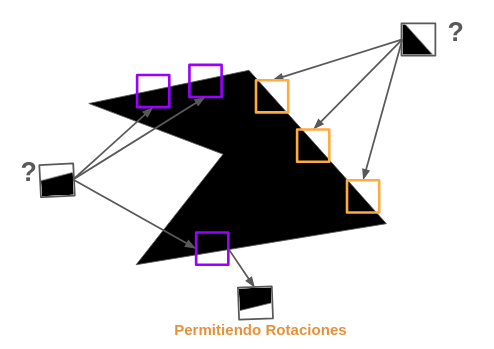


Por otro lado, las esquinas al tener dos direcciones de cambio son mucho mas robustas.

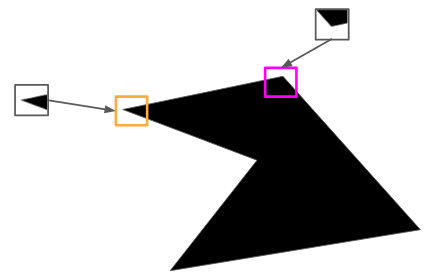




## Configuracion

In [ ]:
from scipy import ndimage
from skimage import filters
from skimage import util
import skimage.io as io
from skimage import feature
from skimage import img_as_ubyte
from skimage import img_as_float

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

from skimage import data
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

import os

## **Ejemplo de Harrys.**

### Calculo de Derivada con Sobel Y Gauss

In [ ]:
#Creamos las 3 posibles tipos de Imagen
imagenConstante = np.zeros((256, 256))

imagenBorde = np.zeros((256, 256))
imagenBorde[:, 128:] = 1

imagenEsquina = np.zeros((256, 256))
imagenEsquina[128:, 128:] = 1

#Calculamos la derivada parcial de cada una
derivadaConstanteY = filters.sobel_h(imagenConstante)
derivadaConstanteX = filters.sobel_v(imagenConstante)

derivadaBordeY = filters.sobel_h(imagenBorde)
derivadaBordeX = filters.sobel_v(imagenBorde)

derivadaEsquinaY = filters.sobel_h(imagenEsquina)
derivadaEsquinaX = filters.sobel_v(imagenEsquina)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
ax = axes.ravel()

ax[0].imshow(imagenConstante, cmap=plt.cm.gray)
ax[1].imshow(imagenBorde, cmap=plt.cm.gray)
ax[2].imshow(imagenEsquina, cmap=plt.cm.gray)


ax[3].imshow(img_as_ubyte(derivadaConstanteX), cmap=plt.cm.gray)
ax[4].imshow(img_as_ubyte(derivadaBordeX), cmap=plt.cm.gray)
ax[5].imshow(img_as_ubyte(derivadaEsquinaX), cmap=plt.cm.gray)


ax[6].imshow(img_as_ubyte(derivadaConstanteY), cmap=plt.cm.gray)
ax[7].imshow(img_as_ubyte(derivadaBordeY), cmap=plt.cm.gray)
ax[8].imshow(img_as_ubyte(derivadaEsquinaY), cmap=plt.cm.gray)

nombres_columnas = ["Constante", "Borde", "Esquina"]
nombres_filas = ["Imagen", "Derivada en X", "Derivada en Y"]
for columna, nombre in enumerate(nombres_columnas): axes[0, columna].set_title(nombre)
for fila, nombre in enumerate(nombres_filas): axes[fila, 0].set_ylabel(nombre)

plt.tight_layout()
plt.show()

### Construimos las Imagenes Necesarias

In [ ]:
#Calculamos cada una de las derivadas a cuadrado
derivadaEsquinaYDoble = derivadaEsquinaY**2
derivadaEsquinaXDoble = derivadaEsquinaX**2
derivadaEsquinaXY = derivadaEsquinaY * derivadaEsquinaX

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(8, 8))
ax = axes.ravel()

#Ploteamos cada una de estas derivadas, notemos como hay un unico punto en derivadaEsquinaXY
ax[0].imshow(derivadaEsquinaYDoble, cmap=plt.cm.gray)
ax[1].imshow(derivadaEsquinaXDoble, cmap=plt.cm.gray)
ax[2].imshow(derivadaEsquinaXY, cmap=plt.cm.gray)
ax[0].set_title("$I_y^2$")
ax[1].set_title("$I_x^2$")
ax[2].set_title("$I_x I_y$")
plt.tight_layout()
plt.show()

### Construimos la Matriz M

In [ ]:
#Definimos el tamano de la ventana
VentanaShape = 20
mitad = VentanaShape//2

#Definimos en donde se centrara la ventana (y,x)
Centro = (128,128)

# Create a Rectangle patch
fig, ax = plt.subplots(1,figsize=(10, 10))

rect = patches.Rectangle((Centro[1]-VentanaShape/2, Centro[0]-VentanaShape/2), VentanaShape, VentanaShape, linewidth=1, edgecolor='r', facecolor='none')
ax.imshow(imagenEsquina, cmap=plt.cm.gray)
ax.add_patch(rect)

plt.show()


#Tomamos la derivada X, Y y XY de la ventana
MatrizM_X = np.sum(derivadaEsquinaXDoble[Centro[0]-mitad:Centro[0]+mitad,
                                         Centro[1]-mitad:Centro[1]+mitad])

MatrizM_Y = np.sum(derivadaEsquinaYDoble[Centro[0]-mitad:Centro[0]+mitad,
                                         Centro[1]-mitad:Centro[1]+mitad])

MatrizM_XY = np.sum(derivadaEsquinaXY[Centro[0]-mitad:Centro[0]+mitad,
                                         Centro[1]-mitad:Centro[1]+mitad])

#Creamos la Matriz M
M = [[MatrizM_X,MatrizM_XY],[MatrizM_XY,MatrizM_Y]]
MatrizM = np.asarray(M)

print()
print(f"Matriz gradiante de la ventana centrada en {Centro} de tamano {VentanaShape}: \n {MatrizM}")

### Calculamos su "esquinidad"

In [ ]:
K = 0.05
R = np.linalg.det(MatrizM) - K * np.trace(MatrizM) ** 2
print(R)

### Moviendo la ventana

Probamos la misma cuenta en cualquier lugar de las tres imágenes. En una **esquina** $R$ es grande y positivo, sobre un **borde** es negativo, y en una zona **constante** es cero.

In [ ]:
imagenes_de_ejemplo = {"Constante": imagenConstante, "Borde": imagenBorde, "Esquina": imagenEsquina}
UMBRAL_PLANO = 1  # por debajo de esto consideramos que R es cero

def calcular_esquinidad(imagen, centro_y, centro_x, tamano, k=0.05):
  derivada_x = filters.sobel_v(imagen)
  derivada_y = filters.sobel_h(imagen)

  mitad = tamano // 2
  ventana = (slice(centro_y - mitad, centro_y + mitad), slice(centro_x - mitad, centro_x + mitad))

  suma_xx = np.sum(derivada_x[ventana] ** 2)
  suma_yy = np.sum(derivada_y[ventana] ** 2)
  suma_xy = np.sum(derivada_x[ventana] * derivada_y[ventana])

  matriz_m = np.array([[suma_xx, suma_xy], [suma_xy, suma_yy]])
  return np.linalg.det(matriz_m) - k * np.trace(matriz_m) ** 2

def mostrar_ventana(tipo_imagen, centro_y, centro_x, tamano):
  esquinidad = calcular_esquinidad(imagenes_de_ejemplo[tipo_imagen], centro_y, centro_x, tamano)

  if esquinidad > UMBRAL_PLANO: clasificacion = "esquina"
  elif esquinidad < -UMBRAL_PLANO: clasificacion = "borde"
  else: clasificacion = "zona constante"

  fig, ax = plt.subplots(figsize=(5, 5))
  ax.imshow(imagenes_de_ejemplo[tipo_imagen], cmap=plt.cm.gray, vmin=0, vmax=1)
  ax.add_patch(patches.Rectangle((centro_x - tamano / 2, centro_y - tamano / 2), tamano, tamano, linewidth=2, edgecolor="r", facecolor="none"))
  ax.set_title(f"R = {esquinidad:.1f}: {clasificacion}")
  plt.show()

interact(
  mostrar_ventana,
  tipo_imagen=Dropdown(options=list(imagenes_de_ejemplo), value="Esquina", description="Imagen"),
  centro_y=IntSlider(min=24, max=232, step=4, value=128, description="Centro y", continuous_update=False),
  centro_x=IntSlider(min=24, max=232, step=4, value=128, description="Centro x", continuous_update=False),
  tamano=IntSlider(min=4, max=40, step=2, value=20, description="Ventana", continuous_update=False),
);

### Harris sobre una foto

Ahora el mismo $R$ calculado en **todos** los píxeles de una foto real, y nos quedamos con los máximos locales como esquinas. Variamos $k$ y la distancia mínima entre esquinas.

In [ ]:
foto_camarografo = img_as_float(data.camera())

def mostrar_harris(k, distancia_minima, umbral_relativo):
  respuesta = feature.corner_harris(foto_camarografo, k=k)
  esquinas = feature.corner_peaks(respuesta, min_distance=distancia_minima, threshold_rel=umbral_relativo)

  fig, (ax_respuesta, ax_foto) = plt.subplots(1, 2, figsize=(11, 5.5))
  ax_respuesta.imshow(np.clip(respuesta, 0, np.percentile(respuesta, 99.9)), cmap="magma")
  ax_respuesta.set_title("Respuesta de Harris ($R > 0$)")
  ax_foto.imshow(foto_camarografo, cmap=plt.cm.gray)
  ax_foto.plot(esquinas[:, 1], esquinas[:, 0], "r+", markersize=9)
  ax_foto.set_title(f"{len(esquinas)} esquinas")
  for eje in (ax_respuesta, ax_foto): eje.axis("off")
  plt.tight_layout()
  plt.show()

interact(
  mostrar_harris,
  k=FloatSlider(min=0.01, max=0.2, step=0.01, value=0.05, description="k", continuous_update=False),
  distancia_minima=IntSlider(min=2, max=30, step=1, value=8, description="Distancia", continuous_update=False),
  umbral_relativo=FloatSlider(min=0.001, max=0.3, step=0.001, value=0.02, description="Umbral", readout_format=".3f", continuous_update=False),
);

# **Histogram of Oriented Gradients (HOG)**

El descriptor **HOG (Histogram of Oriented Gradients)** es una técnica ampliamente utilizada para la **detección de objetos**. Captura la estructura o forma de los objetos a través de la distribución de gradientes de intensidad.



## **¿Qué es HOG?**

La idea principal de HOG es que la **apariencia local** y la **forma** de los objetos pueden describirse bien mediante la distribución de **gradientes** (cambios de intensidad) u **orientaciones de bordes**.


In [ ]:
from skimage import data, color
from skimage.feature import hog
from skimage import exposure
import matplotlib.pyplot as plt

# Cargar imagen de ejemplo en escala de grises
image = color.rgb2gray(data.astronaut())

# Calcular HOG y su visualización
# Usameremos 9 orientaciones, celdas de 8x8 y bloques de 2x2 celdas para la
# normalizacion L2-Hys.
features, hog_image = hog(image,
                          orientations=9,
                          pixels_per_cell=(8, 8),
                          cells_per_block=(2, 2),
                          block_norm='L2-Hys',
                          visualize=True)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].imshow(image, cmap='gray')
axs[0].set_title('Imagen original')
axs[0].axis('off')

axs[1].imshow(hog_image, cmap='gray')
axs[1].set_title('Visualización HOG')
axs[1].axis('off')

fig.tight_layout()
plt.show()

In [ ]:
print(f'Vector de características HOG: {features.shape}')
print(features)

Variamos los parámetros del descriptor y vemos cómo cambia el tamaño del vector. Con celdas chicas hay más detalle, pero el vector crece mucho.

In [ ]:
imagen_astronauta = color.rgb2gray(data.astronaut())

def mostrar_hog(orientaciones, tamano_celda):
  features, hog_image = hog(imagen_astronauta, orientations=orientaciones, pixels_per_cell=(tamano_celda, tamano_celda), cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)

  fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
  axs[0].imshow(imagen_astronauta, cmap='gray')
  axs[0].set_title('Imagen original')
  axs[1].imshow(hog_image, cmap='gray')
  axs[1].set_title(f'HOG: {features.shape[0]} features')
  for eje in axs: eje.axis('off')
  plt.tight_layout()
  plt.show()

interact(
  mostrar_hog,
  orientaciones=IntSlider(min=3, max=12, step=1, value=9, description="Bins", continuous_update=False),
  tamano_celda=Dropdown(options=[4, 8, 16, 32], value=8, description="Celda"),
);

## ¿Por qué no usar una distribución global?

Una distribución global pierde toda la información espacial. Dos imágenes con estructuras muy distintas pueden tener la misma distribución de bordes global.

## **Como calculamos HOG?**:

1. **Preprocesamiento**: Normalización de la imagen (por ejemplo, conversión a escala de grises).
2. **Cálculo de gradientes**: Se usa Sobel o alguna máscara similar.
3. **Celdas**: Dividimos la imagen en pequeñas celdas (por ejemplo, 8x8 píxeles).
4. **Histogramas**: Para cada celda, computamos un histograma de direcciones de gradiente.
5. **Bloques**: Agrupamos celdas en bloques más grandes (por ejemplo, 2x2 celdas), y normalizamos.
6. **Vector final**: Concatenamos todos los histogramas normalizados.


## ***Ejercicio Implementacion: Implementación de HOG***

> Utilizaremos imágenes en escala de grises de tamaño fijo **80x120** píxeles. Para ello, seleccionaremos un recorte o reescalaremos imágenes previamente cargadas.


### **Paso 1: Cargar y preparar la imagen**

> Usaremos la imagen de **Chelsea** (un gato) como ejemplo durante el ejercico. Primero la cargaremos, la pasaremos a escala de grises, y luego la transformaremos a dimensiones **(80, 120)**.



In [ ]:
from skimage import data, color, transform
import matplotlib.pyplot as plt

# Cargar imagen RGB y convertir a escala de grises
image = data.chelsea()  # imagen de un gato
gray = color.rgb2gray(image)

# Reescalar a tamaño fijo (80x120)
resized = transform.resize(gray, (80, 120), anti_aliasing=True)

fig, ax = plt.subplots()
ax.imshow(resized, cmap='gray')
ax.set_title('Imagen 80x120')
ax.axis('off')
plt.show()

### **Paso 2: Calcular los gradientes**

***Ejercicio:*** Implementar el cálculo de gradientes en x e y usando filtros Sobel

> Aplicar los filtros de Sobel para calcular los gradientes en las direcciones horizontal (Gx) y vertical (Gy). Obtener Magnitud y orientacion

In [ ]:
import numpy as np
from scipy import ndimage
from skimage.filters import sobel_h, sobel_v

def obtener_mag_y_orientacion(img):
  # Calcular gradientes
  Gx = #...
  Gy = #...

  # Magnitud y ángulo
  magnitude = #...
  orientation = #...

  # convertimos los ángulos en [0,180)
  orientation = orientation * (180 / np.pi) % 180

  return magnitude, orientation


magnitude, orientation = obtener_mag_y_orientacion(resized)

# Umbral para magnitud
THRESHOLD = 0.1

# Máscara: mantener solo orientaciones con magnitud suficiente
# SOLO PARA FINES VISUALES
orientation_masked = np.where(magnitude > THRESHOLD, orientation, np.nan)

hsv_cmap = plt.get_cmap('hsv').copy()
hsv_cmap.set_bad(color='black')

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

# Mostrar magnitud y orientación
axs[0].imshow(magnitude, cmap='gray')
axs[0].set_title('Magnitud del gradiente')
axs[0].axis('off')

axs[1].imshow(orientation, cmap='hsv')
axs[1].set_title('Orientación del gradiente')
axs[1].axis('off')

axs[2].imshow(orientation_masked, cmap=hsv_cmap)
axs[2].set_title(f'Orientacion (solo > {THRESHOLD})')
axs[2].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
def imagen_con_borde(vertical, lado=16):
  imagen = np.zeros((lado, lado))
  if vertical: imagen[:, lado // 2:] = 1
  else: imagen[lado // 2:, :] = 1
  return imagen

def rampa(pendiente_x, pendiente_y, lado=16):
  filas, columnas = np.mgrid[0:lado, 0:lado]
  return pendiente_x * columnas + pendiente_y * filas

def distancia_angular(angulo, objetivo):
  # Las orientaciones estan en [0, 180): 0 y 180 son la misma direccion
  diferencia = abs(angulo - objetivo) % 180
  return min(diferencia, 180 - diferencia)

def verificar_mag_y_orientacion():
  magnitud, orientacion = obtener_mag_y_orientacion(imagen_con_borde(vertical=True))
  assert magnitud.shape == (16, 16) and orientacion.shape == (16, 16), f"[gradientes] magnitud y orientacion tienen que tener la forma de la imagen (16, 16), se obtuvo {magnitud.shape} y {orientacion.shape}"
  assert orientacion.min() >= 0 and orientacion.max() < 180, f"[gradientes] la orientacion tiene que estar en [0, 180), se obtuvo [{orientacion.min():.1f}, {orientacion.max():.1f}]"
  assert distancia_angular(orientacion[8, 7], 0) < 1, f"[gradientes] un borde vertical tiene el gradiente en la direccion x: se esperaba orientacion 0 y se obtuvo {orientacion[8, 7]:.1f}"
  assert magnitud[8, 7] > 0 and np.allclose(magnitud[8, :6], 0), "[gradientes] la magnitud tiene que ser positiva sobre el borde y cero lejos de el"

  magnitud, orientacion = obtener_mag_y_orientacion(imagen_con_borde(vertical=False))
  assert distancia_angular(orientacion[7, 8], 90) < 1, f"[gradientes] un borde horizontal tiene el gradiente en la direccion y: se esperaba orientacion 90 y se obtuvo {orientacion[7, 8]:.1f}"

  magnitud, _ = obtener_mag_y_orientacion(np.zeros((16, 16)))
  assert np.allclose(magnitud, 0), "[gradientes] una imagen constante no tiene gradiente: la magnitud tiene que ser 0"

  magnitud_en_x, _ = obtener_mag_y_orientacion(rampa(1, 0))
  magnitud_diagonal, orientacion_diagonal = obtener_mag_y_orientacion(rampa(1, 1))
  assert distancia_angular(orientacion_diagonal[8, 8], 45) < 1, f"[gradientes] una rampa en x e y por igual tiene orientacion 45 y se obtuvo {orientacion_diagonal[8, 8]:.1f}"
  assert np.isclose(magnitud_diagonal[8, 8] / magnitud_en_x[8, 8], np.sqrt(2)), f"[gradientes] con Gx = Gy la magnitud es sqrt(2) veces la de Gx solo: se esperaba {np.sqrt(2):.3f} y se obtuvo {magnitud_diagonal[8, 8] / magnitud_en_x[8, 8]:.3f}"

  print("OK [gradientes] magnitud y orientacion correctas en bordes, rampas y zonas constantes")

verificar_mag_y_orientacion()

### **Paso 3: Construir histogramas de orientación**

**Ejercicio:** Dividir la imagen en celdas y calcular histogramas de orientación

> Dividir la imagen en celdas de 8x8 píxeles y calcular un histograma de 9 bins para las orientaciones, realizar la votacion por la magnitud del gradiente.

In [ ]:
# Dado la magnitud y orientacion de cada pixel, el tamaño de las celdas y la cantidad
# de orientaciones, calcula el histograma de orientacion para cada celda.

def computarHistogramaDeCeldas(magnitud, orientacion, cell_size=8, orentacion_bins=9):

  # Podemos suponer que las dimensiones de la imagen sera multiplo de las
  # dimensiones de la celdas.

  # Dividimos la imagen en celdas
  height, width = magnitud.shape
  n_cells_y = height // cell_size
  n_cells_x = width // cell_size

  # Creamos un histograma vacio
  histograms = np.zeros((n_cells_y, n_cells_x, orentacion_bins))

  # Calculamos el ancho de los bind de angulos
  bin_width = 180 // orentacion_bins

  # Calculamos el histograma de cada celda
  for i in range(n_cells_y):
    for j in range(n_cells_x):

      # Calculamos que pixeles formaran parte de la celda
      celda_pixeles_r =(i*cell_size, (i+1)*cell_size)
      celda_pixeles_c =(j*cell_size, (j+1)*cell_size)

      mag_block = magnitud[celda_pixeles_r[0] : celda_pixeles_r[1], celda_pixeles_c[0] : celda_pixeles_c[1]]
      ang_block = orientacion[celda_pixeles_r[0] : celda_pixeles_r[1], celda_pixeles_c[0] : celda_pixeles_c[1]]

      hist = np.zeros(orentacion_bins)

      # COMPLETAR...
        # Por cada pixel de la celda, encontramos su bin correspondiente y
        # agregamos su magnitud al histograma

      histograms[i, j] = hist

  return histograms

cell_histograms = computarHistogramaDeCeldas(magnitude, orientation)
print("Forma del array de histogramas por celda:", cell_histograms.shape)

In [ ]:
def verificar_histograma_de_celdas():
  generador = np.random.default_rng(0)
  magnitud = generador.random((16, 24))
  orientacion = generador.uniform(0, 180, (16, 24))

  histogramas = computarHistogramaDeCeldas(magnitud, orientacion)
  assert histogramas.shape == (2, 3, 9), f"[histogramas] una imagen de 16x24 con celdas de 8x8 tiene 2x3 celdas de 9 bins: se esperaba (2, 3, 9) y se obtuvo {histogramas.shape}"

  for i in range(2):
    for j in range(3):
      celda = (slice(8 * i, 8 * (i + 1)), slice(8 * j, 8 * (j + 1)))
      esperado, _ = np.histogram(orientacion[celda], bins=9, range=(0, 180), weights=magnitud[celda])
      assert np.allclose(histogramas[i, j], esperado), f"[histogramas] la celda ({i}, {j}) no coincide con np.histogram: se esperaba {np.round(esperado, 2)} y se obtuvo {np.round(histogramas[i, j], 2)}"

  # Un pixel por cada borde de bin: cada angulo tiene que votar en el bin de arriba, con su magnitud
  magnitud_borde = np.zeros((8, 8))
  orientacion_borde = np.zeros((8, 8))
  magnitud_borde[0, :4] = [1, 2, 3, 4]
  orientacion_borde[0, :4] = [0, 19.9, 20, 179.9]
  histograma = computarHistogramaDeCeldas(magnitud_borde, orientacion_borde)[0, 0]
  assert np.allclose(histograma, [3, 3, 0, 0, 0, 0, 0, 0, 4]), f"[histogramas] 0 y 19.9 grados van al bin 0, 20 al bin 1 y 179.9 al bin 8: se esperaba [3, 3, 0, 0, 0, 0, 0, 0, 4] y se obtuvo {np.round(histograma, 2)}"

  print("OK [histogramas] cada celda vota por magnitud en el bin que le corresponde")

verificar_histograma_de_celdas()

#### Visualizar HOG
> Podemos representar la orientación dominante de cada celda con una línea cuya longitud esté ponderada por la magnitud acumulada en esa dirección.


In [ ]:
from skimage import draw

def visualize_hog_field(cell_histograms, cell_size=8, bins=9, scale=0.4):

  n_cells_row, n_cells_col, _ = cell_histograms.shape

  s_row = n_cells_row * cell_size
  s_col = n_cells_col * cell_size

  hog_image = np.zeros((s_row, s_col), dtype=np.float32)

  # Parámetros de dibujo
  c_row, c_col = cell_size, cell_size
  radius = cell_size // 2 - 1
  orientations_arr = np.arange(bins)
  orientation_bin_midpoints = np.pi * (orientations_arr + 0.5) / 9

  dr_arr = radius * np.sin(orientation_bin_midpoints)
  dc_arr = radius * np.cos(orientation_bin_midpoints)

  # Dibujar líneas por celda y bin
  for r in range(n_cells_row):
    for c in range(n_cells_col):
      for o, dr, dc in zip(orientations_arr, dr_arr, dc_arr):
        center_r = r * c_row + c_row // 2
        center_c = c * c_col + c_col // 2
        rr, cc = draw.line(
            int(center_r - dc),
            int(center_c + dr),
            int(center_r + dc),
            int(center_c - dr)
        )

        # Acumular intensidad del bin en esa celda
        hog_image[rr, cc] += cell_histograms[r, c, o]

  # Normalizar para visualización
  hog_image /= hog_image.max()

  return hog_image


#### Comparacion Con Scikit Image

In [ ]:

hogImage = visualize_hog_field(cell_histograms, cell_size=8, bins=9)

_, hogimageScikit = hog(resized,
                          orientations=9,
                          pixels_per_cell=(8, 8),
                          cells_per_block=(2, 2),
                          block_norm='L2-Hys',
                          visualize=True)

fig, ax = plt.subplots(1,3,figsize=(10, 4))

ax[0].imshow(resized, cmap='gray')
ax[0].set_title('Imagen original')
ax[0].axis('off')

ax[1].set_facecolor('black')
ax[1].imshow(hogImage, cmap='gray')
ax[1].set_title('HOG')
ax[1].axis('off')

ax[2].imshow(hogimageScikit, cmap='gray')
ax[2].set_title('HOG Scikit')
ax[2].axis('off')

fig.tight_layout()
plt.show()



### **Paso 4: Normalización por bloques**

**Ejercicio**: Normalizar los histogramas por bloques 2x2 celdas

> Aplicar normalización L2 sobre bloques de 2x2 celdas contiguas para obtener invariancia a iluminación y contraste.

In [ ]:
def normalizarBloques(cell_histograms, block_size=2):

  n_cells_y, n_cells_x, bins = cell_histograms.shape

  n_blocks_y = n_cells_y - block_size + 1
  n_blocks_x = n_cells_x - block_size + 1

  features = []

  # Por cada uno de los bloques, encontramos sus celdas y normalizamos
  for i in range(n_blocks_y):
    for j in range(n_blocks_x):
      # Encontramos su celda y las concatenamos
      block = cell_histograms[i:i+block_size, j:j+block_size].ravel()
      # COMPLETAR...
        # Calcular la norma del vector con los histogramas del bloque
        # Normalizar el vector por esta norma
        # Lo agregamos al vector de features de la imagen

  return np.concatenate(features)

hog_features = normalizarBloques(cell_histograms)

print("Tamaño del vector HOG final:", hog_features.shape)



---



# **Detector de Peatones con HOG + MLP**

Con HOG ya entendido, lo usamos para encontrar personas en fotos. El plan tiene cuatro pasos:

> 1. Recortamos **ventanas** de 120x80 píxeles, con peatón y sin peatón, del dataset [`INRIA Person Dataset`](https://lear.inrialpes.fr/data).
> 2. De cada ventana sacamos su descriptor **HOG**: un vector de 4536 números.
> 3. Entrenamos un **MLP en PyTorch** para que diga si ese vector corresponde a un peatón.
> 4. Deslizamos la ventana por una foto completa y dejamos que el MLP decida en cada posición.

El paper original ([Histograms of Oriented Gradients for Human Detection](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf)) usa una SVM lineal como clasificador. Acá lo reemplazamos por el MLP de la clase anterior: HOG hace de extractor de características y el MLP solo ve el vector.

## **Imports**

In [ ]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ipywidgets import interact, Dropdown, FloatSlider, Checkbox

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import nms
from sklearn.model_selection import train_test_split

from skimage import io, color, transform, util
from skimage.feature import hog

## **Estilo de los gráficos**

In [ ]:
#@title Paleta y estilo { display-mode: "form" }

# Los mismos colores de la clase de MLP: azul para "no peatón", naranja para "peatón"
COLOR_CLASE_0 = "#2B6CB0"
COLOR_CLASE_1 = "#E8871E"
COLOR_TINTA = "#1F2933"

plt.rcParams.update({
  "figure.facecolor": "white",
  "axes.facecolor": "white",
  "axes.edgecolor": COLOR_TINTA,
  "axes.labelcolor": COLOR_TINTA,
  "axes.titlelocation": "left",
  "axes.titleweight": "bold",
  "axes.titlesize": 12,
  "axes.spines.top": False,
  "axes.spines.right": False,
  "text.color": COLOR_TINTA,
  "xtick.color": COLOR_TINTA,
  "ytick.color": COLOR_TINTA,
  "font.size": 11,
})

## **Carga de Imágenes**

El dataset está en el repositorio de la materia, dentro de `Laboratorio_5_Harris_HOG/Peatones`:

- **Train/pos**: 2188 recortes de 160x96 con un peatón centrado.
- **Train/neg**: 1198 fotos de 240x320 sin personas.
- **Test/pos** y **Test/neg**: fotos completas para probar el detector al final.

Esta celda las descarga (funciona en Colab y localmente). Si la carpeta ya existe no vuelve a descargar nada.

In [ ]:
#@title Descargar las imagenes { display-mode: "form" }
import os
import urllib.request
import zipfile

REPOSITORIO_URL = "https://github.com/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim"  #@param {type:"string"}
RAMA = "main"  #@param {type:"string"}
CARPETA_EN_REPOSITORIO = "Laboratorio_5_Harris_HOG/Peatones"  #@param {type:"string"}
CARPETA_PEATONES = "Peatones"  # carpeta local con Train/pos, Train/neg, Test/pos y Test/neg

def descargar_carpeta_de_github(url_zip, carpeta_en_repositorio, carpeta_local):
  # El zip del repositorio pesa cientos de MB: lo guardamos en disco en lugar de tenerlo entero en memoria
  ruta_zip, _ = urllib.request.urlretrieve(url_zip)
  prefijo = carpeta_en_repositorio.strip("/") + "/"

  with zipfile.ZipFile(ruta_zip) as zip_repositorio:
    for nombre in zip_repositorio.namelist():
      # El zip de GitHub tiene todo dentro de una carpeta raiz: <repo>-<rama>/<carpeta_en_repositorio>/archivo
      ruta = nombre.split("/", 1)[1] if "/" in nombre else ""
      if ruta.startswith(prefijo) and not ruta.endswith("/"):
        destino = os.path.join(carpeta_local, ruta[len(prefijo):])
        os.makedirs(os.path.dirname(destino), exist_ok=True)
        with open(destino, "wb") as salida:
          salida.write(zip_repositorio.read(nombre))
  os.remove(ruta_zip)

if os.path.isdir(CARPETA_PEATONES):
  print(f"La carpeta {CARPETA_PEATONES} ya existe, no se descarga nada")
else:
  descargar_carpeta_de_github(f"{REPOSITORIO_URL.rstrip('/')}/archive/refs/heads/{RAMA}.zip", CARPETA_EN_REPOSITORIO, CARPETA_PEATONES)
  print(f"Descargadas las imagenes en {CARPETA_PEATONES}")

## **De la imagen al descriptor**

Todo el trabajo de la parte 1 queda resumido en una función: `calcular_hog` recibe una ventana en escala de grises de 120x80 y devuelve su vector de 4536 números (con los mismos parámetros de antes: 9 bins, celdas de 8x8 y bloques de 2x2).

Las ventanas con peatón son el recorte central de cada foto de `Train/pos`. Las ventanas sin peatón salen de recortes al azar de `Train/neg`; las **reescalamos** antes de recortar porque más adelante vamos a mirar cada foto a varios tamaños.

In [ ]:
ALTO_VENTANA = 120
ANCHO_VENTANA = 80
ESCALA_MINIMA_NEGATIVOS = 0.6  # con menos de esto, las fotos de 240x320 no alcanzan para recortar una ventana

def listar_imagenes(carpeta):
  return sorted(os.path.join(carpeta, nombre) for nombre in os.listdir(carpeta) if nombre.lower().endswith((".png", ".jpg", ".jpeg")))

def leer_en_gris(ruta):
  imagen = io.imread(ruta)
  if imagen.ndim == 3 and imagen.shape[2] == 4: imagen = color.rgba2rgb(imagen)
  if imagen.ndim == 3: return color.rgb2gray(imagen)
  return util.img_as_float(imagen)

def calcular_hog(ventana):
  return hog(ventana, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")

def recortar_centro(imagen):
  alto, ancho = imagen.shape
  inicio_y = (alto - ALTO_VENTANA) // 2
  inicio_x = (ancho - ANCHO_VENTANA) // 2
  return imagen[inicio_y:inicio_y + ALTO_VENTANA, inicio_x:inicio_x + ANCHO_VENTANA]

def recortar_al_azar(imagen, generador):
  escala = generador.uniform(ESCALA_MINIMA_NEGATIVOS, 1.0)
  reescalada = transform.rescale(imagen, escala, anti_aliasing=True)

  alto, ancho = reescalada.shape
  inicio_y = generador.integers(0, alto - ALTO_VENTANA + 1)
  inicio_x = generador.integers(0, ancho - ANCHO_VENTANA + 1)
  return reescalada[inicio_y:inicio_y + ALTO_VENTANA, inicio_x:inicio_x + ANCHO_VENTANA]

In [ ]:
#@title Ejemplos de ventanas y su HOG { display-mode: "form" }

def graficar_ejemplos(ventanas, titulos):
  fig, ejes = plt.subplots(2, len(ventanas), figsize=(2.2 * len(ventanas), 5.2))
  for columna, (ventana, titulo) in enumerate(zip(ventanas, titulos)):
    _, imagen_hog = hog(ventana, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    ejes[0, columna].imshow(ventana, cmap="gray")
    ejes[0, columna].set_title(titulo, color=COLOR_CLASE_1 if titulo == "Peatón" else COLOR_CLASE_0)
    ejes[1, columna].imshow(imagen_hog, cmap="gray")
    ejes[0, columna].axis("off")
    ejes[1, columna].axis("off")
  fig.tight_layout()
  plt.show()

generador_ejemplos = np.random.default_rng(3)
ventanas_positivas = [recortar_centro(leer_en_gris(ruta)) for ruta in listar_imagenes("Peatones/Train/pos")[::600][:4]]
ventanas_negativas = [recortar_al_azar(leer_en_gris(ruta), generador_ejemplos) for ruta in listar_imagenes("Peatones/Train/neg")[::300][:4]]

graficar_ejemplos(ventanas_positivas + ventanas_negativas, ["Peatón"] * 4 + ["No peatón"] * 4)

## **Dataset**

Calculamos el HOG de todas las ventanas. Tarda un par de minutos: es lo más lento del laboratorio y solo se hace una vez.

Tomamos 3 ventanas por cada foto sin personas, así que hay más negativos que positivos. Después lo compensamos en la loss.

In [ ]:
SEMILLA = 11  #@param {type:"integer"}
VENTANAS_NEGATIVAS_POR_IMAGEN = 3  #@param {type:"integer"}

def cargar_descriptores_positivos(carpeta):
  descriptores = [calcular_hog(recortar_centro(leer_en_gris(ruta))) for ruta in listar_imagenes(carpeta)]
  return np.array(descriptores)

def cargar_descriptores_negativos(carpeta, ventanas_por_imagen, generador):
  descriptores = []
  for ruta in listar_imagenes(carpeta):
    imagen = leer_en_gris(ruta)
    for _ in range(ventanas_por_imagen):
      descriptores.append(calcular_hog(recortar_al_azar(imagen, generador)))
  return np.array(descriptores)

generador = np.random.default_rng(SEMILLA)
inicio = time.time()

descriptores_positivos = cargar_descriptores_positivos("Peatones/Train/pos")
descriptores_negativos = cargar_descriptores_negativos("Peatones/Train/neg", VENTANAS_NEGATIVAS_POR_IMAGEN, generador)

print(f"Positivos: {descriptores_positivos.shape}, Negativos: {descriptores_negativos.shape} ({time.time() - inicio:.0f} s)")

In [ ]:
# Igual que en la clase de MLP: un Dataset para acceder a las features y la clase de forma conjunta
class VentanasDataset(Dataset):
  def __init__(self, X, y):
    self.X = X
    self.y = y

  def __len__(self):
    return len(self.X)

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]


X = torch.tensor(np.concatenate([descriptores_positivos, descriptores_negativos]), dtype=torch.float32)
y = torch.tensor(np.concatenate([np.ones(len(descriptores_positivos)), np.zeros(len(descriptores_negativos))]), dtype=torch.float32).reshape(-1, 1)

# stratify mantiene la misma proporcion de peatones en train y en test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

train_loader = DataLoader(VentanasDataset(X_train, y_train), batch_size=64, shuffle=True)
test_loader = DataLoader(VentanasDataset(X_test, y_test), batch_size=64, shuffle=False)

print(f"Train: {len(X_train)} ventanas, Test: {len(X_test)} ventanas")

## **El MLP**

La entrada es el vector HOG (4536 números) y la salida un único **logit**: positivo significa "peatón". Son dos capas ocultas con `ReLU`, como en la clase anterior pero más anchas.

In [ ]:
class Net(nn.Module):
  def __init__(self, input_features, size_hidden_1=64, size_hidden_2=16, n_output=1):
    super().__init__()
    self.hidden1 = nn.Linear(input_features, size_hidden_1)
    self.hidden2 = nn.Linear(size_hidden_1, size_hidden_2)
    self.out = nn.Linear(size_hidden_2, n_output)
    self.activacion = nn.ReLU()

  # La salida son logits: la sigmoide la aplica la loss
  def forward(self, x):
    h1 = self.activacion(self.hidden1(x))
    h2 = self.activacion(self.hidden2(h1))
    return self.out(h2)


torch.manual_seed(SEMILLA)
modelo = Net(X_train.shape[1])

print(modelo)
print(f"Parametros entrenables: {sum(parametro.numel() for parametro in modelo.parameters())}")

### Entrenamiento

Es clasificación binaria, así que usamos `BCEWithLogitsLoss` como en la clase. Como hay más ventanas sin peatón que con peatón, `pos_weight` hace que equivocarse con un peatón pese más en la loss. Si no, a la red le conviene responder siempre "no hay nadie".

In [ ]:
def evaluar(modelo, loader, criterio):
  modelo.eval()
  loss_total, aciertos, total = 0.0, 0, 0
  with torch.no_grad():
    for batch_X, batch_y in loader:
      logits = modelo(batch_X)
      loss_total += criterio(logits, batch_y).item() * len(batch_y)
      aciertos += ((logits > 0).float() == batch_y).sum().item()
      total += len(batch_y)
  return loss_total / total, aciertos / total


def entrenar(modelo, train_loader, test_loader, criterio, epocas, learning_rate):
  optimizer = torch.optim.Adam(modelo.parameters(), lr=learning_rate)

  # La posicion 0 de cada lista es el modelo sin entrenar
  historial = {"loss_train": [], "loss_test": [], "accuracy_train": [], "accuracy_test": []}

  def registrar_epoca():
    loss_train, accuracy_train = evaluar(modelo, train_loader, criterio)
    loss_test, accuracy_test = evaluar(modelo, test_loader, criterio)
    historial["loss_train"].append(loss_train)
    historial["loss_test"].append(loss_test)
    historial["accuracy_train"].append(accuracy_train)
    historial["accuracy_test"].append(accuracy_test)
    return loss_train, loss_test, accuracy_test

  registrar_epoca()

  for epoca in range(1, epocas + 1):
    modelo.train()
    for batch_X, batch_y in train_loader:

      optimizer.zero_grad()

      logits = modelo(batch_X)

      loss = criterio(logits, batch_y)

      # Calcular Gradientes
      loss.backward()

      # Actualizo los pesos
      optimizer.step()

    loss_train, loss_test, accuracy_test = registrar_epoca()
    print(f"Epoch {epoca}, Train Loss: {loss_train:.4f}, Test Loss: {loss_test:.4f}, Test Accuracy: {accuracy_test:.2%}")

  return historial

In [ ]:
EPOCAS = 8
LEARNING_RATE = 1e-3

criterio = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(len(descriptores_negativos) / len(descriptores_positivos)))

historial = entrenar(modelo, train_loader, test_loader, criterio, EPOCAS, LEARNING_RATE)

In [ ]:
#@title Curvas de entrenamiento { display-mode: "form" }

def graficar_curvas(historial):
  epocas = np.arange(len(historial["loss_train"]))

  fig, (ax_loss, ax_accuracy) = plt.subplots(1, 2, figsize=(12, 4))

  ax_loss.plot(epocas, historial["loss_train"], color=COLOR_TINTA, linewidth=2, label="Train")
  ax_loss.plot(epocas, historial["loss_test"], color=COLOR_TINTA, linewidth=2, linestyle="--", alpha=0.55, label="Test")
  ax_loss.set_title("Loss")
  ax_loss.set_xlabel("Época")

  ax_accuracy.plot(epocas, historial["accuracy_train"], color=COLOR_TINTA, linewidth=2, label="Train")
  ax_accuracy.plot(epocas, historial["accuracy_test"], color=COLOR_TINTA, linewidth=2, linestyle="--", alpha=0.55, label="Test")
  ax_accuracy.set_title("Accuracy")
  ax_accuracy.set_xlabel("Época")
  ax_accuracy.set_ylim(0.4, 1.02)

  for ax in (ax_loss, ax_accuracy):
    ax.legend(frameon=False)

  fig.tight_layout()
  plt.show()


graficar_curvas(historial)

La loss de train sigue bajando pero la de test deja de mejorar y después empeora: la red empieza a **memorizar** las ventanas de entrenamiento. Por eso entrenamos pocas épocas. Probá subir `EPOCAS` a 30 y mirá cómo se separan las curvas.

## **Detectar peatones en una foto**

El MLP solo sabe mirar una ventana de 120x80. Para buscar en una foto completa:

> **Deslizar:** recorremos la foto con una ventana, de a 16 píxeles, y le calculamos al MLP la probabilidad de peatón en cada posición.
\
> **Cambiar de escala:** los peatones aparecen de distintos tamaños, así que repetimos la búsqueda con la foto achicada varias veces.
\
> **Umbral:** nos quedamos con las ventanas cuya probabilidad supera un valor.
\
> **Fusionar:** una misma persona aparece en varias ventanas vecinas. *Non-maximum suppression* deja solo la de mayor probabilidad de cada grupo.

El cálculo más pesado (HOG y MLP sobre cada ventana) se hace **una sola vez por foto**. Después podés mover el umbral sin esperar.

In [ ]:
LADO_MAXIMO_FOTO = 640  # achicamos las fotos grandes para que la busqueda no tarde
ESCALAS = [1.0, 0.75, 0.55, 0.4, 0.3]
PASO = 16
SUPERPOSICION_MAXIMA = 0.3  # IoU a partir del cual dos cajas se consideran la misma persona

def leer_foto(ruta):
  foto = io.imread(ruta)
  if foto.ndim == 2: foto = color.gray2rgb(foto)
  foto = foto[..., :3]

  escala = min(1.0, LADO_MAXIMO_FOTO / max(foto.shape[:2]))
  return transform.rescale(foto, escala, channel_axis=2, anti_aliasing=True)

def puntuar_ventanas(modelo, foto_gris, escala):
  reescalada = transform.rescale(foto_gris, escala, anti_aliasing=True)
  alto, ancho = reescalada.shape

  posiciones = [(y, x) for y in range(0, alto - ALTO_VENTANA + 1, PASO) for x in range(0, ancho - ANCHO_VENTANA + 1, PASO)]
  if not posiciones: return np.zeros((0, 4)), np.zeros(0)

  descriptores = np.array([calcular_hog(reescalada[y:y + ALTO_VENTANA, x:x + ANCHO_VENTANA]) for y, x in posiciones])
  with torch.no_grad():
    probabilidades = torch.sigmoid(modelo(torch.tensor(descriptores, dtype=torch.float32)))[:, 0].numpy()

  # Las cajas se devuelven en coordenadas de la foto original (x0, y0, x1, y1)
  cajas = np.array([[x, y, x + ANCHO_VENTANA, y + ALTO_VENTANA] for y, x in posiciones]) / escala
  return cajas, probabilidades

def puntuar_foto(modelo, foto):
  modelo.eval()
  foto_gris = color.rgb2gray(foto)

  resultados = [puntuar_ventanas(modelo, foto_gris, escala) for escala in ESCALAS]
  cajas = np.concatenate([cajas_escala for cajas_escala, _ in resultados])
  probabilidades = np.concatenate([probabilidades_escala for _, probabilidades_escala in resultados])
  return cajas, probabilidades

def filtrar_detecciones(cajas, probabilidades, umbral, fusionar):
  superan_umbral = probabilidades > umbral
  cajas, probabilidades = cajas[superan_umbral], probabilidades[superan_umbral]

  if fusionar:
    conservar = nms(torch.tensor(cajas, dtype=torch.float32), torch.tensor(probabilidades, dtype=torch.float32), SUPERPOSICION_MAXIMA).numpy()
    cajas, probabilidades = cajas[conservar], probabilidades[conservar]
  return cajas, probabilidades

### Probamos el detector

Elegí una foto y movés el umbral: con un umbral bajo aparecen falsos positivos, con uno muy alto se pierden peatones. Las fotos `neg` no tienen personas: ahí lo ideal es no ver ninguna caja. La primera vez que abrís una foto tarda unos segundos.

In [ ]:
fotos_de_ejemplo = {
  f"{carpeta}/{os.path.basename(ruta)}": ruta
  for carpeta, indice_salto in (("pos", 24), ("neg", 90))
  for ruta in listar_imagenes(f"Peatones/Test/{carpeta}")[::indice_salto]
}
puntajes_por_foto = {}

def mostrar_detecciones(ruta, umbral, fusionar):
  if ruta not in puntajes_por_foto:
    foto = leer_foto(ruta)
    puntajes_por_foto[ruta] = (foto, *puntuar_foto(modelo, foto))
  foto, cajas, probabilidades = puntajes_por_foto[ruta]

  cajas, probabilidades = filtrar_detecciones(cajas, probabilidades, umbral, fusionar)

  fig, ax = plt.subplots(figsize=(9, 6.5))
  ax.imshow(foto)
  for (x0, y0, x1, y1), probabilidad in zip(cajas, probabilidades):
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=COLOR_CLASE_1, linewidth=2.5))
    ax.text(x0 + 3, y0 + 3, f"{probabilidad:.3f}", color="white", fontsize=9, va="top", bbox=dict(facecolor=COLOR_CLASE_1, edgecolor="none", pad=1.5))
  ax.set_title(f"{len(cajas)} {'detección' if len(cajas) == 1 else 'detecciones'} con probabilidad > {umbral:.3f}")
  ax.axis("off")
  plt.show()

interact(
  mostrar_detecciones,
  ruta=Dropdown(options=fotos_de_ejemplo, description="Foto"),
  umbral=FloatSlider(min=0.5, max=0.999, step=0.001, value=0.99, description="Umbral", readout_format=".3f", continuous_update=False),
  fusionar=Checkbox(value=True, description="Fusionar cajas"),
);